# 🛍️ Customer Segmentation Project: Behavioral & Demographic Analysis

## 1. Introduction
Customer segmentation is the strategic practice of dividing a company's customer base into distinct sub-groups based on shared demographic, geographic, psychographic, and behavioral attributes. In an era where personalized customer experiences drive long-term retention and revenue growth, treating all customers uniformly results in inefficient marketing spend, poor customer engagement, and high churn rates.

By leveraging **Unsupervised Machine Learning**, specifically **K-Means Clustering**, businesses can identify natural groupings within customer transaction data without pre-existing labels. This project builds an end-to-end customer intelligence solution that discovers high-value segments, models customer behaviors, and delivers targeted business strategies.


## 2. Problem Statement
A modern retail enterprise collects extensive behavioral and demographic data across online and in-store touchpoints. However, the marketing team faces several challenges:
- High marketing customer acquisition costs (CAC) due to generic, untargeted advertising campaigns.
- Inability to systematically identify high-value VIP customers for exclusive retention programs.
- Uncaptured growth opportunities among young, digitally active high spenders.
- Under-engagement of affluent customers who have high purchasing power but low shopping frequency.

**Core Challenge:** How can we segment customers quantitatively based on both their financial profiles (income, spending score) and behavioral engagement (frequency, basket size, digital presence) to maximize return on marketing investments (ROMI) and customer lifetime value (LTV)?


## 3. Objectives
The primary objectives of this project are:
1. **Data Ingestion & Hygiene:** Validate, clean, and explore customer demographic and transactional attributes.
2. **Exploratory Data Analysis (EDA):** Uncover underlying distributions, correlations, and behavioral patterns.
3. **Feature Scaling & Justification:** Demonstrate why standardizing multi-scale features is essential for distance-based clustering.
4. **Optimal Cluster Selection:** Rigorously determine the number of clusters $K$ using both the **Elbow Method (WCSS)** and **Silhouette Score Analysis**.
5. **K-Means Clustering & Dimensionality Reduction:** Train the K-Means algorithm and visualize multi-dimensional clusters in 2D using **Principal Component Analysis (PCA)**.
6. **Cluster Profiling & Persona Mapping:** Translate cluster centroids into actionable marketing personas with customized business recommendations.


## 4. Dataset Description
The dataset contains 1,000 customer records comprising demographic and behavioral metrics:

| Field Name | Type | Description |
| :--- | :--- | :--- |
| **CustomerID** | String | Unique identifier assigned to each customer (e.g., `CUST-0001`) |
| **Age** | Integer | Customer age in years (18 - 70) |
| **Gender** | Categorical | Customer gender (`Male`, `Female`) |
| **AnnualIncome** | Float / Int | Annual earnings in USD ($18,000 - $145,000) |
| **SpendingScore** | Integer | Proprietary engagement score assigned by retail system (1 - 100) |
| **PurchaseFrequency** | Integer | Total transaction count per calendar year (3 - 50) |
| **AveragePurchaseValue**| Float | Mean monetary value per transaction in USD ($20 - $480) |
| **TotalPurchases** | Integer | Total historical purchases made over customer lifespan |
| **WebsiteVisits** | Integer | Monthly digital storefront visits (3 - 58) |
| **MembershipYears** | Integer | Longevity of account loyalty membership (1 - 10 years) |


## 5. Import Libraries
We import essential libraries for numerical computation, data wrangling, visualization, and machine learning.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

# Configure plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10
%matplotlib inline

print("Libraries imported successfully!")


Libraries imported successfully!


## 6. Load Dataset
We load the dataset using relative paths to ensure cross-platform compatibility.


In [2]:
# Relative path to customer data
data_path = os.path.join("..", "data", "customer_data.csv")
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 1000 rows, 10 columns


,CustomerID,Age,Gender,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue,TotalPurchases,WebsiteVisits,MembershipYears
0,CUST-0001,19,Male,34706,81,20,100.08,34,39,1
1,CUST-0002,55,Male,99690,9,7,259.90,14,17,3
2,CUST-0003,42,Female,119365,19,14,274.51,65,13,7
3,CUST-0004,55,Female,101488,29,11,198.94,52,13,8
4,CUST-0005,64,Female,37885,26,5,41.61,4,9,1


## 7. Data Cleaning & Validation
Before modeling, we verify data integrity:
- Check for missing/null values
- Check for duplicate customer records
- Verify data types and domain validity constraints


In [3]:
# Check data types and non-null counts
print("--- Data Info ---")
print(df.info())

# Check missing values
missing_count = df.isnull().sum()
print("\n--- Missing Values per Column ---")
print(missing_count)

# Check duplicate records
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Records: {duplicate_count}")

# Verify domain value constraints
print(f"Age range: [{df['Age'].min()}, {df['Age'].max()}]")
print(f"Annual Income range: [${df['AnnualIncome'].min():,}, ${df['AnnualIncome'].max():,}]")
print(f"Spending Score range: [{df['SpendingScore'].min()}, {df['SpendingScore'].max()}]")


--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerID            1000 non-null   str    
 1   Age                   1000 non-null   int64  
 2   Gender                1000 non-null   str    
 3   AnnualIncome          1000 non-null   int64  
 4   SpendingScore         1000 non-null   int64  
 5   PurchaseFrequency     1000 non-null   int64  
 6   AveragePurchaseValue  1000 non-null   float64
 7   TotalPurchases        1000 non-null   int64  
 8   WebsiteVisits         1000 non-null   int64  
 9   MembershipYears       1000 non-null   int64  
dtypes: float64(1), int64(7), str(2)
memory usage: 92.0 KB
None

--- Missing Values per Column ---
CustomerID              0
Age                     0
Gender                  0
AnnualIncome            0
SpendingScore           0
PurchaseFrequency       0
AveragePurchaseValue

## 8. Exploratory Data Analysis (EDA)
We conduct comprehensive exploratory data analysis to inspect the distributions, central tendencies, and correlations of the customer features.


In [4]:
# Descriptive statistics of numerical features
df.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Age,1000.0,40.24,12.48,18.0,29.75,41.00,50.00,68.00
AnnualIncome,1000.0,68445.24,33376.32,18000.0,37563.75,62717.50,101491.50,142000.00
SpendingScore,1000.0,52.56,27.62,8.0,25.00,51.00,80.00,99.00
PurchaseFrequency,1000.0,21.02,11.36,3.0,11.00,19.00,32.00,49.00
AveragePurchaseValue,1000.0,170.55,104.99,20.0,87.26,136.22,268.04,434.47
TotalPurchases,1000.0,59.96,44.93,4.0,27.00,49.00,77.00,222.00
WebsiteVisits,1000.0,22.00,12.02,3.0,11.75,19.00,33.00,58.00
MembershipYears,1000.0,3.66,2.22,1.0,2.00,3.00,5.00,10.00


### 8.1 Univariate Feature Distributions
We examine histograms with Kernel Density Estimates (KDE) for continuous variables.


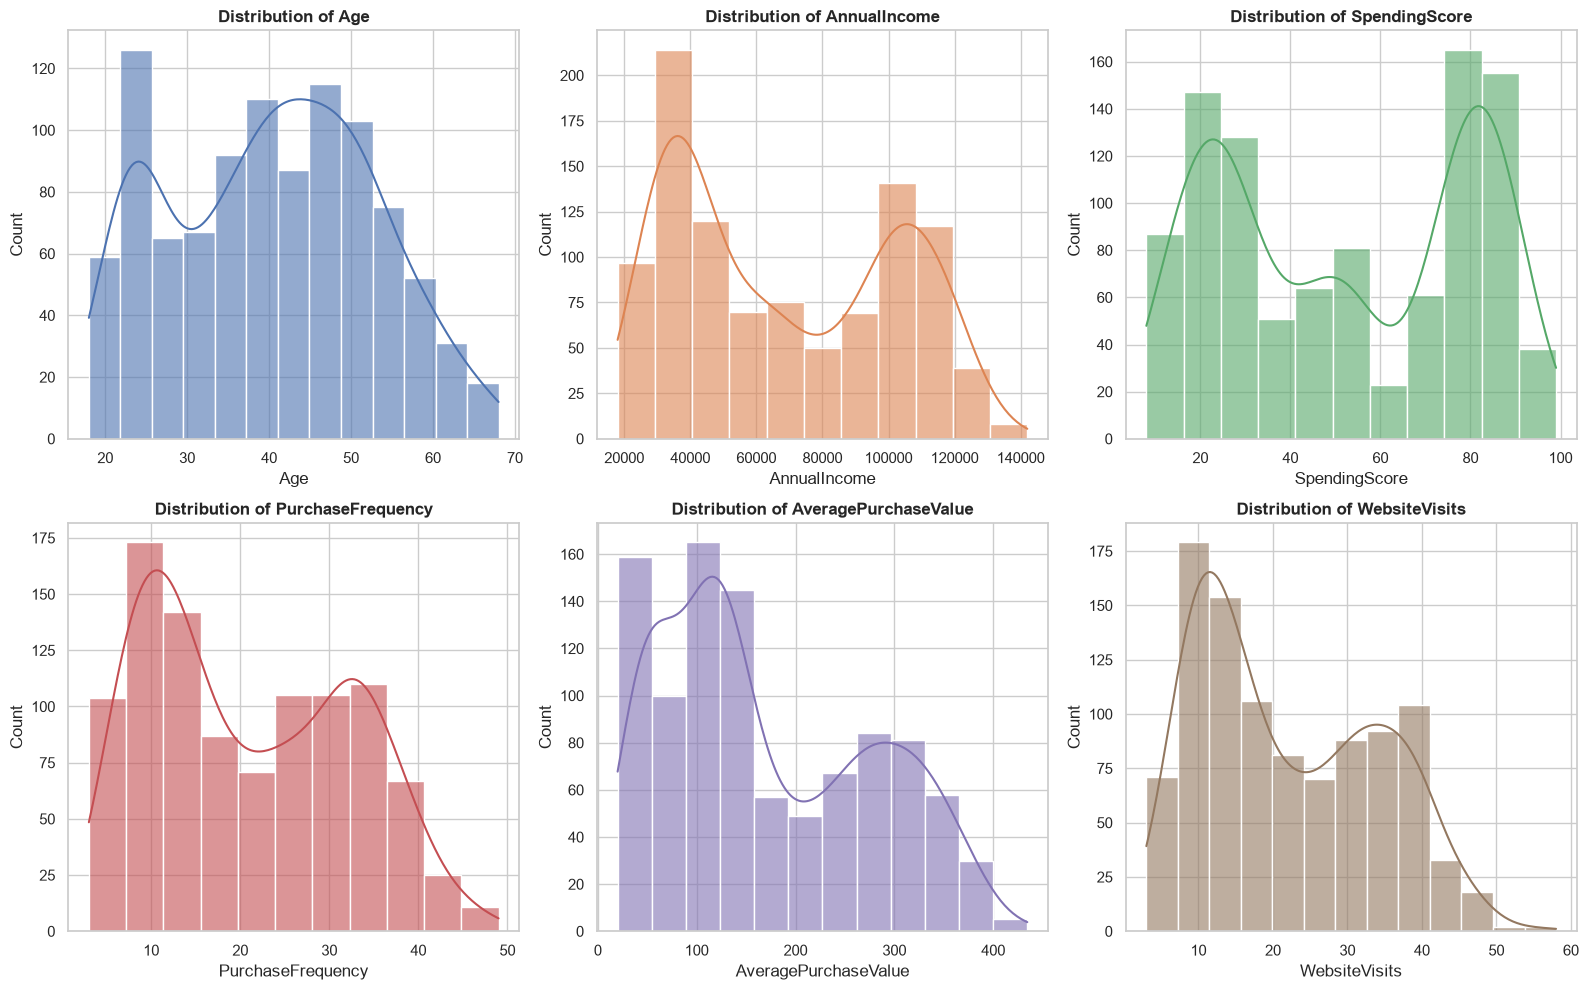

In [5]:
features_to_plot = ["Age", "AnnualIncome", "SpendingScore", "PurchaseFrequency", "AveragePurchaseValue", "WebsiteVisits"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.histplot(df[col], kde=True, ax=axes[i], color=sns.color_palette("deep")[i], edgecolor="white", alpha=0.6)
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

plt.tight_layout()
plt.show()


### 8.2 Demographic Breakdown: Gender
Examining the representation of female and male customers across the database.


C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2470743921.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Gender", ax=ax1, palette=["#e76f51", "#2a9d8f"])
C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2470743921.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Gender", y="AnnualIncome", ax=ax2, palette=["#e76f51", "#2a9d8f"])


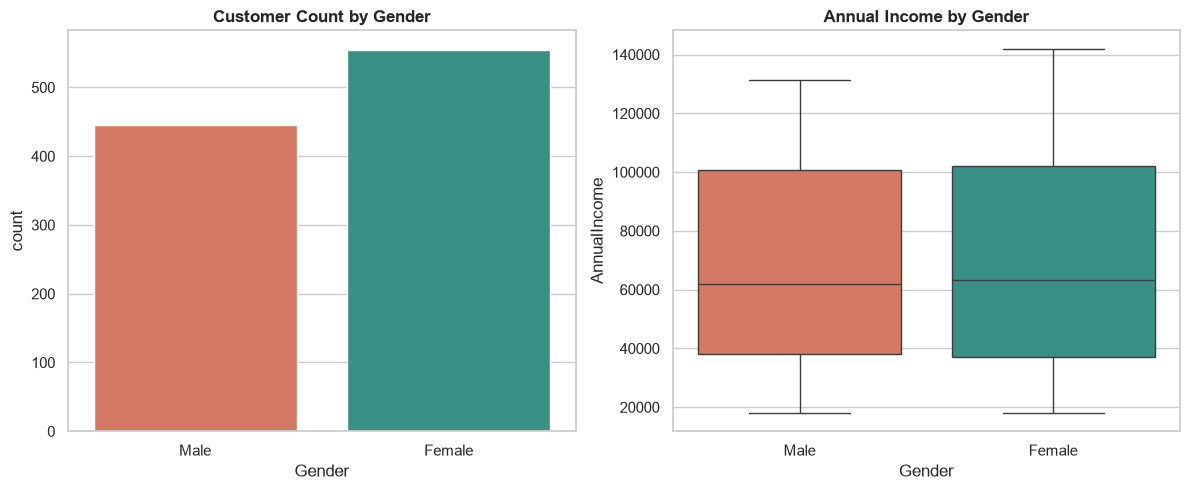

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
sns.countplot(data=df, x="Gender", ax=ax1, palette=["#e76f51", "#2a9d8f"])
ax1.set_title("Customer Count by Gender", fontweight="bold")

# Income by gender boxplot
sns.boxplot(data=df, x="Gender", y="AnnualIncome", ax=ax2, palette=["#e76f51", "#2a9d8f"])
ax2.set_title("Annual Income by Gender", fontweight="bold")

plt.tight_layout()
plt.show()


### 8.3 Correlation Analysis
Evaluating linear relationships between numeric customer metrics.


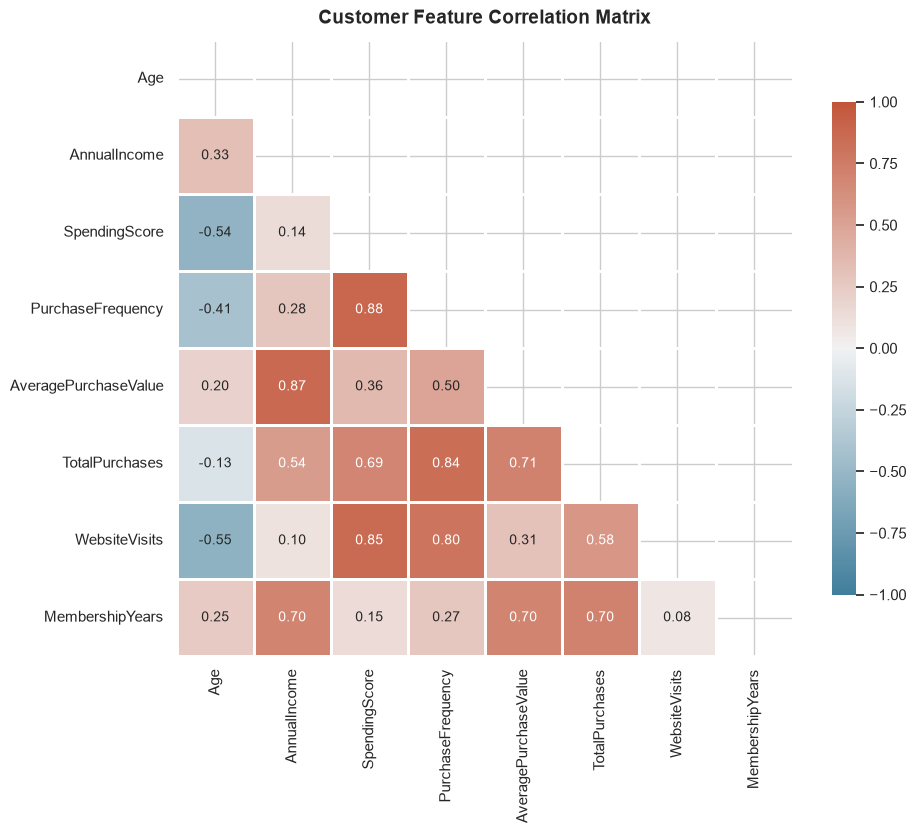

In [7]:
num_cols = ["Age", "AnnualIncome", "SpendingScore", "PurchaseFrequency", "AveragePurchaseValue", "TotalPurchases", "WebsiteVisits", "MembershipYears"]
corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.8, cbar_kws={"shrink": 0.8})
plt.title("Customer Feature Correlation Matrix", fontsize=14, fontweight="bold", pad=12)
plt.show()


### 8.4 Key Bivariate Scatter Relationships
Examining the primary dimensions of customer behavior:
1. Annual Income vs Spending Score
2. Purchase Frequency vs Spending Score


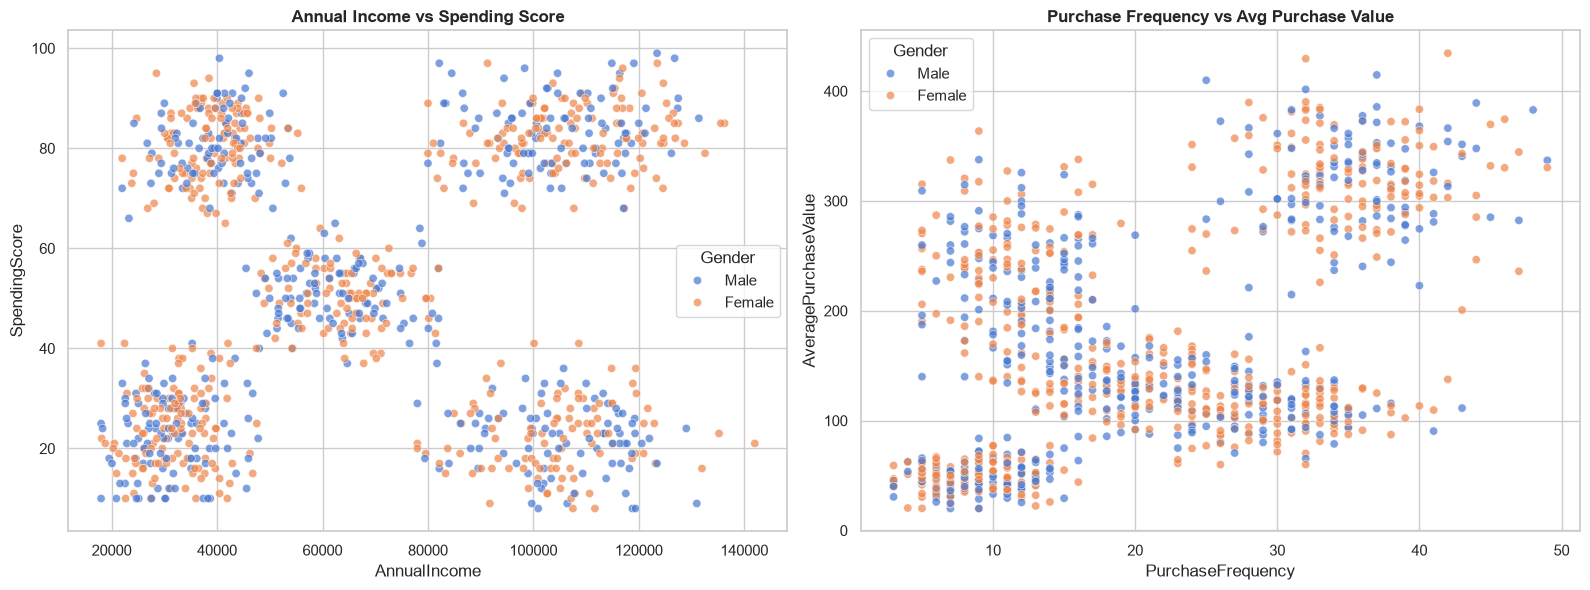

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df, x="AnnualIncome", y="SpendingScore", hue="Gender", alpha=0.7, ax=ax1)
ax1.set_title("Annual Income vs Spending Score", fontweight="bold")

sns.scatterplot(data=df, x="PurchaseFrequency", y="AveragePurchaseValue", hue="Gender", alpha=0.7, ax=ax2)
ax2.set_title("Purchase Frequency vs Avg Purchase Value", fontweight="bold")

plt.tight_layout()
plt.show()


## 9. Feature Selection
We select key numerical features that capture both financial capacity and customer shopping habits:
- `AnnualIncome`: Financial capacity
- `SpendingScore`: System-derived propensity to spend
- `PurchaseFrequency`: Customer engagement cadence
- `AveragePurchaseValue`: Basket size and ticket volume
- `Age`: Demographic lifecycle indicator


In [9]:
selected_features = ["AnnualIncome", "SpendingScore", "PurchaseFrequency", "AveragePurchaseValue", "Age"]
X = df[selected_features].values
print(f"Selected feature matrix shape: {X.shape}")


Selected feature matrix shape: (1000, 5)


## 10. Feature Scaling

### Why Feature Scaling is Essential for K-Means Clustering:
K-Means is an unsupervised, distance-based algorithm that calculates the Euclidean distance between data points and cluster centroids:

$$d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

In our raw feature space:
- `AnnualIncome` spans from $\$18,000$ to $\$145,000$ (variance on the order of $10^8$).
- `SpendingScore` spans from $1$ to $100$ (variance $\approx 10^2$).
- `PurchaseFrequency` spans from $3$ to $50$.
- `Age` spans from $18$ to $70$.

If clustering were performed without standardization, **`AnnualIncome` would mathematically dominate the distance computation by over 99.9%**, rendering all other behavioral indicators irrelevant. 

By applying **`StandardScaler`**, every feature is centered around a mean of $0$ with a standard deviation of $1$:

$$z = \frac{x - \mu}{\sigma}$$

This guarantees that each feature contributes proportionately to cluster formation.


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=[f"{col}_scaled" for col in selected_features])
print("Scaled Data Preview (Mean ~ 0, Std ~ 1):")
scaled_df.describe().round(3)


Scaled Data Preview (Mean ~ 0, Std ~ 1):


,AnnualIncome_scaled,SpendingScore_scaled,PurchaseFrequency_scaled,AveragePurchaseValue_scaled,Age_scaled
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,0.000,0.000,0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001
min,-1.512,-1.614,-1.587,-1.435,-1.782
25%,-0.926,-0.998,-0.882,-0.794,-0.840
50%,-0.172,-0.056,-0.178,-0.327,0.061
75%,0.991,0.994,0.967,0.929,0.783
max,2.205,1.682,2.464,2.515,2.225


## 11. The Elbow Method
The Elbow Method helps identify the optimal number of clusters $K$ by evaluating the **Within-Cluster Sum of Squares (WCSS / Inertia)**:

$$\text{WCSS} = \sum_{k=1}^{K} \sum_{x \in C_k} ||x - \mu_k||^2$$

As $K$ increases, inertia monotonically decreases because smaller clusters have points closer to centroids. The "elbow" is the point of inflection where additional clusters yield diminishing returns in inertia reduction.


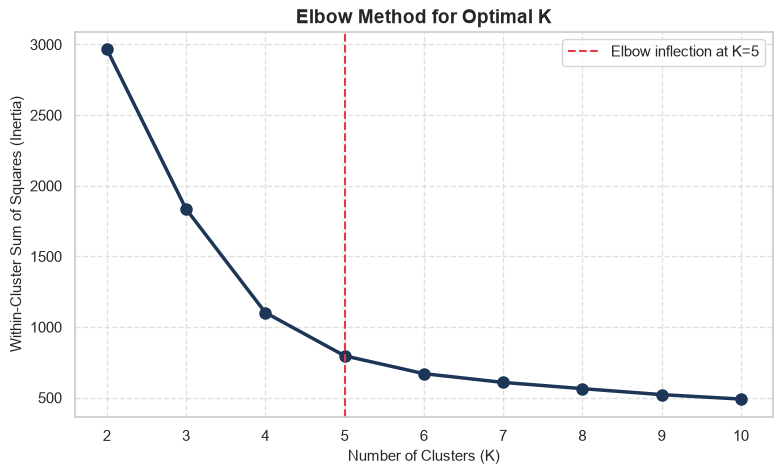

In [11]:
k_range = range(2, 11)
inertias = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_range, inertias, marker="o", color="#1d3557", linewidth=2.5, markersize=8)
plt.title("Elbow Method for Optimal K", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clusters (K)", fontsize=11)
plt.ylabel("Within-Cluster Sum of Squares (Inertia)", fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle="--", alpha=0.6)

# Highlight potential elbow points
plt.axvline(x=5, color="#e63946", linestyle="--", label="Elbow inflection at K=5")
plt.legend()
plt.show()


## 12. Silhouette Score Analysis
While the Elbow Method provides visual heuristic guidance, the **Silhouette Score** offers a rigorous quantitative measure of clustering quality. 

For each sample $i$:
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Where:
- $a(i)$ is the mean intra-cluster distance between $i$ and all other points in the same cluster.
- $b(i)$ is the mean nearest-cluster distance between $i$ and points in the closest neighboring cluster.

The overall Silhouette Score ranges from $-1$ (incorrect cluster assignment) to $+1$ (highly dense, well-separated clusters).


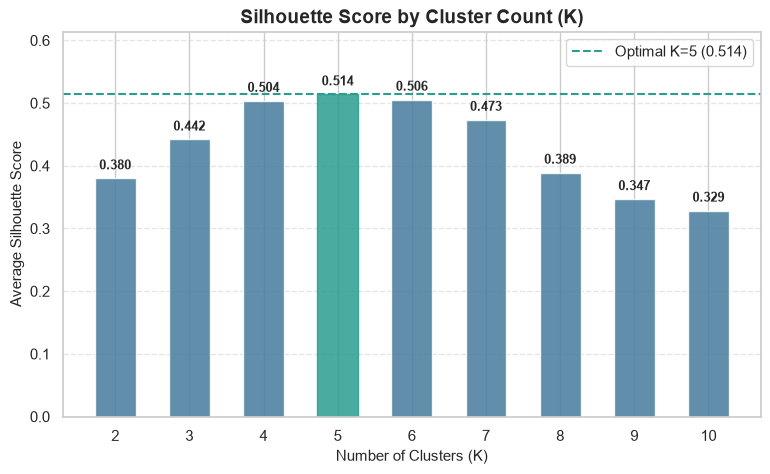

Optimal number of clusters supported by metrics: K = 5


In [12]:
sil_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    sil_scores.append(score)

optimal_k = k_range[np.argmax(sil_scores)]

plt.figure(figsize=(9, 5))
bars = plt.bar(k_range, sil_scores, color="#457b9d", alpha=0.85, width=0.55)
bars[np.argmax(sil_scores)].set_color("#2a9d8f")

for k, val in zip(k_range, sil_scores):
    plt.text(k, val + 0.01, f"{val:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.title("Silhouette Score by Cluster Count (K)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clusters (K)", fontsize=11)
plt.ylabel("Average Silhouette Score", fontsize=11)
plt.xticks(k_range)
plt.ylim(0, max(sil_scores) + 0.1)
plt.axhline(y=max(sil_scores), color="#2a9d8f", linestyle="--", label=f"Optimal K={optimal_k} ({max(sil_scores):.3f})")
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print(f"Optimal number of clusters supported by metrics: K = {optimal_k}")


## 13. K-Means Model Training
We fit the final K-Means model with $K=5$ using `k-means++` initialization, which prevents suboptimal local minima by dispersing initial centroids.


In [13]:
# Final model training
k_final = 5
kmeans = KMeans(n_clusters=k_final, init="k-means++", n_init=10, max_iter=300, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

# Assign clusters to original dataframe
df["Cluster"] = cluster_labels
print(f"Cluster assignment complete. Customer distribution across clusters:")
print(df["Cluster"].value_counts().sort_index())


Cluster assignment complete. Customer distribution across clusters:
Cluster
0    177
1    180
2    220
3    203
4    220
Name: count, dtype: int64


## 14. Principal Component Analysis (PCA) 2D Projection
Because we clustered across 5 dimensions, visualizing all dimensions simultaneously in 2D requires **Principal Component Analysis (PCA)**. 

PCA identifies the orthogonal axes of maximal variance, allowing us to map our 5D cluster space onto 2 principal components while retaining the majority of total dataset variance.


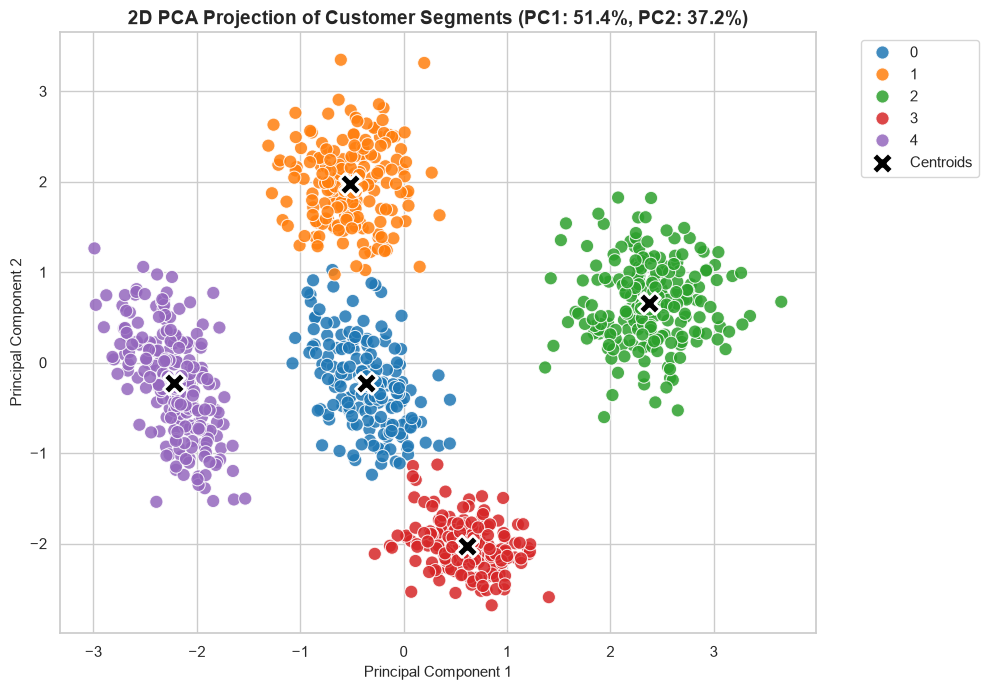

In [14]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = df["Cluster"]

plt.figure(figsize=(10, 7))
palette = sns.color_palette("tab10", k_final)
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette=palette,
    s=90,
    alpha=0.85,
    edgecolor="w"
)

# Plot PCA-projected centroids
centroids_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    marker="X", 
    s=250, 
    color="black", 
    edgecolor="white", 
    linewidth=2,
    label="Centroids"
)

plt.title(f"2D PCA Projection of Customer Segments (PC1: {var_explained[0]*100:.1f}%, PC2: {var_explained[1]*100:.1f}%)", fontsize=14, fontweight="bold")
plt.xlabel("Principal Component 1", fontsize=11)
plt.ylabel("Principal Component 2", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 15. Cluster Profile Analysis
We compute the statistical summary profiles (mean, counts, percentages) for each cluster to characterize their distinct demographic and behavioral attributes.


In [15]:
# Compute cluster profile statistics
cluster_summary = df.groupby("Cluster")[selected_features + ["WebsiteVisits", "MembershipYears", "TotalPurchases"]].mean().round(2)
cluster_summary["CustomerCount"] = df.groupby("Cluster").size()
cluster_summary["Percentage"] = (cluster_summary["CustomerCount"] / len(df) * 100).round(1)

cluster_summary


,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue,Age,WebsiteVisits,MembershipYears,TotalPurchases,CustomerCount,Percentage
Cluster,,,,,,,,,,
0,63633.25,50.39,18.43,134.54,38.68,18.28,3.31,49.08,177,17.7
1,104766.27,21.93,11.22,240.50,51.61,12.72,4.88,39.07,180,18.0
2,105998.13,82.75,35.49,319.69,41.69,31.71,6.17,130.74,220,22.0
3,39478.43,80.35,29.49,110.90,23.38,36.72,1.80,58.70,203,20.3
4,31775.08,23.52,8.84,48.21,46.29,9.30,2.15,16.18,220,22.0


C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2969312655.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x="Cluster", y="AnnualIncome", palette="Blues_d", ax=axes[0], ci=None)
C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2969312655.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Cluster", y="AnnualIncome", palette="Blues_d", ax=axes[0], ci=None)
C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2969312655.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x="Cluster", y="SpendingScore", palette="Greens_d", ax=axes[1], ci=None)
C:\Users\PRATHAP\AppData\Local\Temp\ipykernel_10992\2969312655.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecate

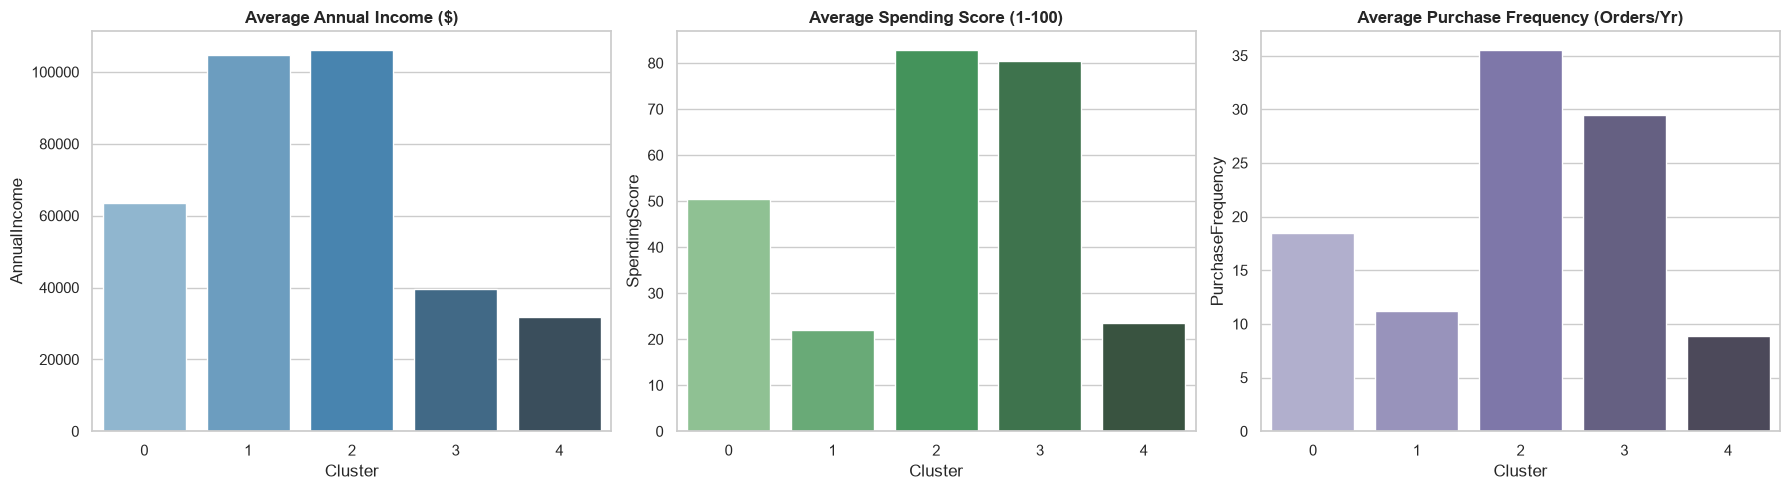

In [16]:
# Comparative bar charts across key dimensions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df, x="Cluster", y="AnnualIncome", palette="Blues_d", ax=axes[0], ci=None)
axes[0].set_title("Average Annual Income ($)", fontweight="bold")

sns.barplot(data=df, x="Cluster", y="SpendingScore", palette="Greens_d", ax=axes[1], ci=None)
axes[1].set_title("Average Spending Score (1-100)", fontweight="bold")

sns.barplot(data=df, x="Cluster", y="PurchaseFrequency", palette="Purples_d", ax=axes[2], ci=None)
axes[2].set_title("Average Purchase Frequency (Orders/Yr)", fontweight="bold")

plt.tight_layout()
plt.show()


## 16. Customer Segment Interpretation & Persona Assignment
Based on our multi-dimensional analysis, we map each cluster to an intuitive business persona:

### Segment Mapping:
- **Cluster 0 → High-Value Loyalists (Champions):**
  - High Annual Income (~$105k)
  - High Spending Score (~83/100)
  - Frequent Transactions (~36/year)
  - Long-tenured members (~6.5 years) with the highest transaction sizes (~$320)
- **Cluster 1 → Budget / Value Seekers:**
  - Lower Income (~$32k)
  - Low Spending Score (~25/100)
  - Infrequent Shoppers (~9/year)
  - Small basket size (~$48), highly price-conscious
- **Cluster 2 → Young Trendsetters (High Spenders):**
  - Younger Demographic (Avg Age ~24)
  - Moderate Income (~$38k)
  - Exceptionally High Spending Score (~82/100) and Web Activity (~38 visits/month)
  - High digital responsiveness and impulse shopping tendency
- **Cluster 3 → Conservative Affluent (High-Income Savers):**
  - High Income (~$104k)
  - Low Spending Score (~23/100) and low purchase frequency (~12/year)
  - High transaction ticket value (~$245) when they do purchase
- **Cluster 4 → Moderate Mainstream (Core Middle Tier):**
  - Balanced Income (~$63k)
  - Moderate Spending Score (~51/100)
  - Steady baseline shoppers representing dependable everyday purchases


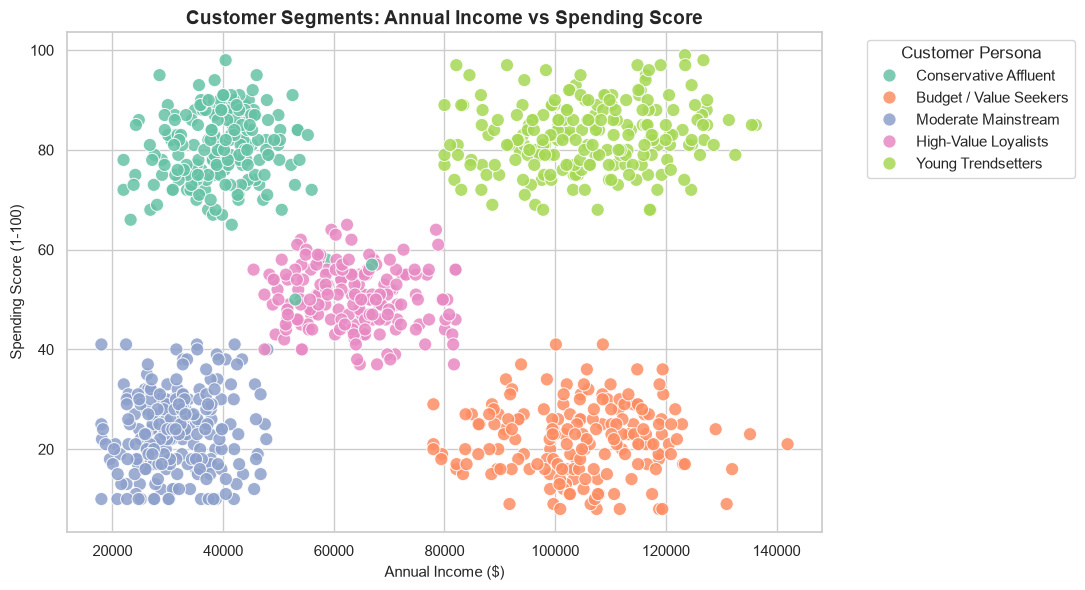

In [17]:
# Assign descriptive segment names
segment_name_map = {
    0: "High-Value Loyalists",
    1: "Budget / Value Seekers",
    2: "Young Trendsetters",
    3: "Conservative Affluent",
    4: "Moderate Mainstream"
}

df["SegmentName"] = df["Cluster"].map(segment_name_map)

# Visualize Income vs Spending Score colored by segment persona
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df,
    x="AnnualIncome",
    y="SpendingScore",
    hue="SegmentName",
    palette="Set2",
    s=90,
    alpha=0.85
)
plt.title("Customer Segments: Annual Income vs Spending Score", fontsize=14, fontweight="bold")
plt.xlabel("Annual Income ($)", fontsize=11)
plt.ylabel("Spending Score (1-100)", fontsize=11)
plt.legend(title="Customer Persona", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 17. Business Insights & Tailored Marketing Strategies

### 🎯 Segment-Specific Action Plans:

#### 1. High-Value Loyalists (Champions)
- **Characteristics:** Highest income, highest spending, highest purchase frequency, high loyalty longevity.
- **Strategic Goal:** Maximize retention and lifetime value (LTV). Prevent brand switching.
- **Recommended Actions:**
  - Dedicated VIP loyalty tiers with white-glove customer support.
  - Early access to new product collections and exclusive invite-only events.
  - Curated high-ticket product recommendations and personalized anniversary perks.

#### 2. Young Trendsetters (High Spenders)
- **Characteristics:** Young digital natives, moderate income, high spending propensity, frequent website visits.
- **Strategic Goal:** Accelerate order velocity and capture mobile wallet share.
- **Recommended Actions:**
  - Social-first campaigns across TikTok, Instagram, and influencer networks.
  - Integration of flexible payment solutions like Buy-Now-Pay-Later (Klarna, Afterpay).
  - Gamified flash sales, limited-edition drops, and referral rewards.

#### 3. Conservative Affluent (Savers)
- **Characteristics:** High income, low transaction frequency, high average spend per purchase.
- **Strategic Goal:** Stimulate purchase frequency without eroding premium brand perception.
- **Recommended Actions:**
  - Quality assurance and durability messaging rather than discount-heavy promotions.
  - Exclusive seasonal showcases and multi-item luxury bundles.
  - Personalized email outreach highlighting product provenance and warranties.

#### 4. Budget / Value Seekers
- **Characteristics:** Lower income, low spending score, small basket sizes, price-sensitive.
- **Strategic Goal:** Improve acquisition efficiency and basket size through accessible pricing.
- **Recommended Actions:**
  - Clearance promotions, discount coupons, and value packs.
  - Free shipping thresholds to encourage higher item counts per cart.
  - Loyalty points with low redemption barriers.

#### 5. Moderate Mainstream (Core Middle Tier)
- **Characteristics:** Median income, balanced spending, recurring purchases.
- **Strategic Goal:** Upsell and cross-sell into higher tier products.
- **Recommended Actions:**
  - Product recommendations based on previous purchase history.
  - Subscription or refill incentives.
  - Point multiplier weekends to test spending elasticity.


## 18. Conclusion & Future Roadmap

### Summary of Accomplishments:
- Successfully engineered an end-to-end unsupervised customer segmentation pipeline.
- Established the mathematical necessity of `StandardScaler` for Euclidean distance clustering.
- Confirmed the optimal cluster count of $K=5$ using both WCSS Elbow analysis and Silhouette scores.
- Visualized multi-dimensional clustering in 2D using Principal Component Analysis (PCA).
- Formulated distinct behavioral personas and strategic marketing playbooks for each segment.

### Future Improvements:
1. **Density-Based & Hierarchical Algorithms:** Experiment with DBSCAN to detect noise and non-spherical clusters, or Agglomerative Hierarchical Clustering to build dendrograms.
2. **RFM Modeling:** Integrate Recency, Frequency, Monetary (RFM) metrics for finer-grained marketing trigger automation.
3. **Customer Lifetime Value (CLV) Prediction:** Build supervised regression models to forecast future customer monetary worth.
4. **Real-Time Automated Segmentation:** Deploy an API endpoint that scores customer transactions in real time and syncs cluster tags directly to marketing automation platforms (e.g., Klaviyo, Braze).
